# Exercise 1 (Total 30 points)



In [2]:
%matplotlib inline

In [4]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:

import warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (train_test_split, cross_val_score, validation_curve,
                                     KFold, StratifiedKFold)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.dummy import DummyClassifier, DummyRegressor

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42                                    # one seed for the whole notebook
CV_REG = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
CV_CLS = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
plt.rcParams["figure.figsize"] = [12, 6]
plt.rcParams["font.size"] = 12


def plot_validation_curve(param_range, train_scores, val_scores, xlabel, ylabel="score",
                          logx=False, ax=None, labels=None):
    # Mean ± 1 std of training and validation (CV) scores, as in Lecture 1.
    ax = ax or plt.gca()
    x = np.arange(len(param_range)) if labels is not None else param_range
    for s, lab, mk in ((train_scores, "training", "o-"), (val_scores, "cross-validation", "s-")):
        m, sd = s.mean(axis=1), s.std(axis=1)
        ax.plot(x, m, mk, label=lab)
        ax.fill_between(x, m - sd, m + sd, alpha=0.2)
    best = int(np.argmax(val_scores.mean(axis=1)))
    ax.axvline(x[best], ls="--", c="k", lw=1, label=f"best = {param_range[best]}")
    if logx: ax.set_xscale("log")
    if labels is not None:
        ax.set_xticks(x); ax.set_xticklabels(labels)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.legend()
    return param_range[best]

## Task 1 (5 points): Regression

##### Dataset: Superconductivity
* Number of records: 21263
* Number of features: 81 + 1 (target/output feature)
* Repository URL: https://archive.ics.uci.edu/ml/datasets/Superconductivty+Data

##### Problems
__a.__ Train two regression models to predict the critical temperature. Report the score with the default parameters of each model.\
__b.__ Perform a simple manual optimization for one of the default parameters (at least 5 different values) and plot the new obtained scores as a function of the chosen parameter. Plot the coefficient magnitudes for the best obtained model.

In [8]:
# Load train.csv (81 material features + critical_temp). unique_m.csv (chemical formulas) is not needed.
if Path("train.csv").exists():
    df_sc = pd.read_csv("train.csv")
else:
    with zipfile.ZipFile("superconductivtydata_1.zip") as z:
        df_sc = pd.read_csv(z.open("train.csv"))

print(df_sc.shape)
print("missing values:", df_sc.isna().sum().sum())
df_sc["critical_temp"].describe().round(2)

(21263, 82)
missing values: 0


count    21263.00
mean        34.42
std         34.25
min          0.00
25%          5.36
50%         20.00
75%         63.00
max        185.00
Name: critical_temp, dtype: float64

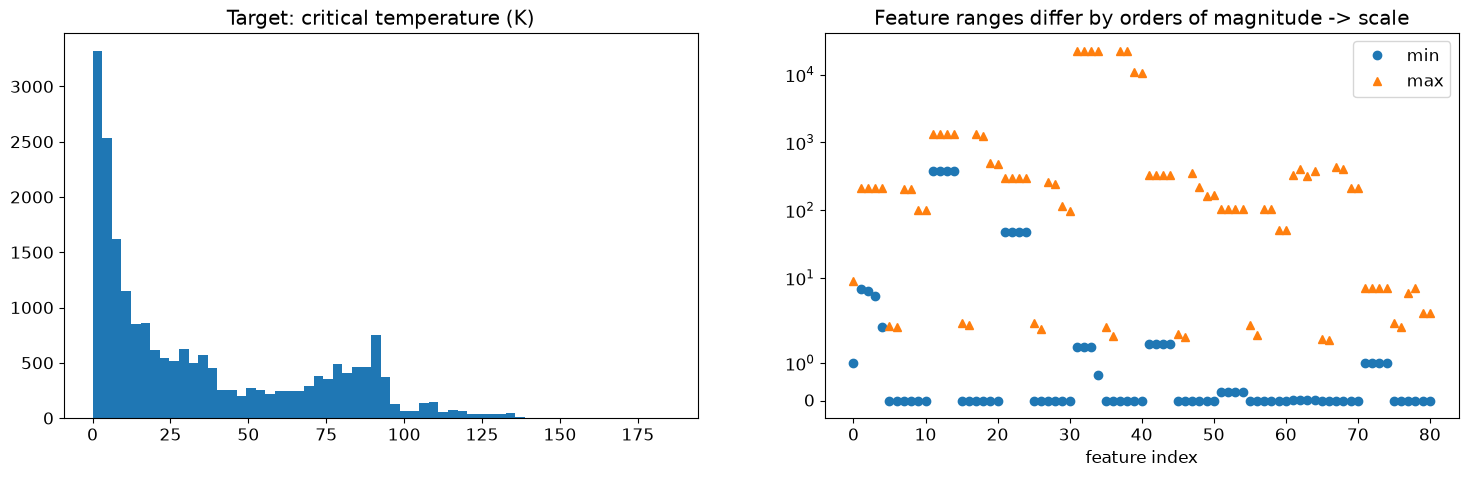

train: (15947, 81)  test: (5316, 81)


In [9]:
X_sc = df_sc.drop(columns="critical_temp")
y_sc = df_sc["critical_temp"].to_numpy()
sc_names = X_sc.columns.to_list()

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
axes[0].hist(y_sc, bins=60); axes[0].set_title("Target: critical temperature (K)")
axes[1].plot(X_sc.min().to_numpy(), "o", label="min"); axes[1].plot(X_sc.max().to_numpy(), "^", label="max")
axes[1].set_yscale("symlog"); axes[1].set_title("Feature ranges differ by orders of magnitude -> scale")
axes[1].set_xlabel("feature index"); axes[1].legend()
plt.show()

X_tr, X_te, y_tr, y_te = train_test_split(X_sc.to_numpy(), y_sc, test_size=0.25, random_state=RANDOM_STATE)
print("train:", X_tr.shape, " test:", X_te.shape)

### a. Two regression models with default parameters

We use the two regularised linear models from Lecture 1, **Ridge** (L2) and **Lasso** (L1), each in a pipeline with `StandardScaler` (the features live on very different scales). The model *parameters* are left at their defaults (`alpha=1.0`). The score is $R^2$ (`.score()` of a regressor); RMSE is shown too because it is in kelvin and easy to interpret. A `DummyRegressor` (always predicts the training mean) is the baseline.

In [10]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_squared_error

reg_models = {
    "Dummy (mean)":     DummyRegressor(),
    "Ridge (default)":  make_pipeline(StandardScaler(), Ridge()),
    "Lasso (default)":  make_pipeline(StandardScaler(), Lasso()),
}

rows = {}
for name, model in reg_models.items():
    cv_r2 = cross_val_score(model, X_tr, y_tr, cv=CV_REG, scoring="r2")
    model.fit(X_tr, y_tr)
    rows[name] = {"CV R² (train, 5-fold)": cv_r2.mean(),
                  "train R²": model.score(X_tr, y_tr),
                  "test R²": model.score(X_te, y_te),
                  "test RMSE (K)": np.sqrt(mean_squared_error(y_te, model.predict(X_te)))}
results_t1a = pd.DataFrame(rows).T.round(3)
results_t1a

,"CV R² (train, 5-fold)",train R²,test R²,test RMSE (K)
Dummy (mean),-0.000,0.000,-0.000,34.008
Ridge (default),0.737,0.739,0.727,17.753
Lasso (default),0.653,0.654,0.650,20.121


**Comment (a).** Both linear models are far better than the baseline. Ridge with its default `alpha=1` explains about **73 %** of the variance of the critical temperature on the test set ($R^2$ = 0.727, RMSE ≈ 17.8 K). Lasso with the default `alpha=1` is clearly worse (test $R^2$ = 0.650, RMSE ≈ 20.1 K): on standardised features `alpha=1` is a strong L1 penalty that sets most coefficients to exactly zero (only 17 of 81 features are kept), so the model *underfits*. Train and test scores are almost identical for both models, which also points to underfitting (high bias), not overfitting. This makes `alpha` of the Lasso the natural parameter to optimise.

### b. Manual optimisation of `alpha` (Lasso)

We try 8 values of the regularisation strength `alpha` (default = 1). Following the lecture, the choice is made with **5-fold cross-validation on the training set** (`validation_curve`); the test set is only used for the final model. `max_iter` is increased only so that the coordinate-descent solver converges for small `alpha`.

In [11]:
alphas = [0.001, 0.01, 0.05, 0.1, 0.5, 1, 2, 5]
lasso_pipe = make_pipeline(StandardScaler(), Lasso(max_iter=50_000))

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    tr_s, va_s = validation_curve(lasso_pipe, X_tr, y_tr, param_name="lasso__alpha",
                                  param_range=alphas, cv=CV_REG, scoring="r2", n_jobs=-1)
    test_s = [make_pipeline(StandardScaler(), Lasso(alpha=a, max_iter=50_000)).fit(X_tr, y_tr).score(X_te, y_te)
              for a in alphas]

fig, ax = plt.subplots(figsize=(12, 6))
best_alpha = plot_validation_curve(alphas, tr_s, va_s, "Lasso alpha (log scale)", "R²", logx=True, ax=ax)
ax.plot(alphas, test_s, "d:", c="tab:green", label="test (for information only)")
ax.legend(); ax.set_title("Lasso: R² as a function of alpha")
plt.show()

pd.DataFrame({"alpha": alphas, "train R²": tr_s.mean(1), "CV R²": va_s.mean(1), "test R²": test_s}).round(4)

KeyboardInterrupt: 

In [ ]:
best_lasso = make_pipeline(StandardScaler(), Lasso(alpha=best_alpha, max_iter=50_000)).fit(X_tr, y_tr)
default_lasso = reg_models["Lasso (default)"]
print(f"best alpha = {best_alpha}")
print(f"best Lasso   : test R² = {best_lasso.score(X_te, y_te):.3f}, "
      f"RMSE = {np.sqrt(mean_squared_error(y_te, best_lasso.predict(X_te))):.2f} K, "
      f"non-zero coefficients = {np.sum(best_lasso[-1].coef_ != 0)}/{len(sc_names)}")
print(f"default Lasso: test R² = {default_lasso.score(X_te, y_te):.3f}, "
      f"non-zero coefficients = {np.sum(default_lasso[-1].coef_ != 0)}/{len(sc_names)}")

In [ ]:
# Coefficient magnitudes of the best model (standardised features -> coefficients are comparable)
coef_best = best_lasso[-1].coef_
order = np.argsort(np.abs(coef_best))[::-1]

fig, axes = plt.subplots(2, 1, figsize=(20, 13))
axes[0].plot(coef_best, "o", label=f"Lasso alpha={best_alpha} (best)", markersize=8)
axes[0].plot(default_lasso[-1].coef_, "^", label="Lasso alpha=1 (default)", markersize=8)
axes[0].axhline(0, c="k", lw=1)
axes[0].set_xlabel("feature index"); axes[0].set_ylabel("coefficient")
axes[0].set_title("Coefficients of all 81 features"); axes[0].legend()

top = order[:25]
axes[1].bar(range(len(top)), np.abs(coef_best[top]),
            color=["tab:blue" if c > 0 else "tab:red" for c in coef_best[top]])
axes[1].set_xticks(range(len(top))); axes[1].set_xticklabels(np.array(sc_names)[top], rotation=60, ha="right")
axes[1].set_ylabel("|coefficient|  (blue = positive, red = negative)")
axes[1].set_title(f"Best model: 25 largest coefficient magnitudes")
plt.tight_layout(); plt.show()

**Comment (b).** The validation curve shows the classic regularisation trade-off from the lecture: a large `alpha` shrinks too many coefficients to zero (underfitting, low train *and* CV $R^2$); decreasing `alpha` steadily improves the score until it levels off at the smallest values, where the Lasso approaches ordinary least squares. The best cross-validated value (`alpha = 0.001`) raises the test $R^2$ from 0.650 (default) to **0.728** (RMSE 20.1 K → 17.7 K) and keeps 80 of the 81 features — the same level as Ridge. Train and CV curves stay close together, so even the least regularised model does not overfit — with 16 000 training samples and 81 features there is enough data, and the remaining error is the bias of a *linear* model (critical temperature is a non-linear function of the material properties; a tree ensemble would do better).

The coefficient plot shows that the default Lasso uses only a handful of features, while the best model spreads weight over many of them. Several of the largest coefficients come in **pairs with opposite signs** (the two largest are `wtd_gmean_atomic_radius` ≈ –77 and `wtd_mean_atomic_radius` ≈ +73). These features are strongly correlated, so individual coefficients should not be over-interpreted; atomic-radius, valence, electron-affinity, atomic-mass, fusion-heat and thermal-conductivity features carry the largest weights.

## Task 2 (10 points): Multiclass & binary classification

##### Dataset:  Drug consumption (quantified)
* Number of records: 1885
* Number of features: 12 + 18 (target/output features)
* Repository URL: https://archive.ics.uci.edu/ml/datasets/Drug+consumption+%28quantified%29
* Reference: Fehrman, Elaine, Awaz K. Muhammad, Evgeny M. Mirkes, Vincent Egan, and Alexander N. Gorban. "The five factor model of personality and evaluation of drug consumption risk." In Data science: innovative developments in data analysis and clustering, pp. 231-242. Springer International Publishing, 2017.

##### Problems
__a.__ Select 2 out of 18 output features, then predict each selected feature by using a multiclass classification model. (Hint: Use numerical values to represent each class of an output feature) Report the accuracy with the default parameters of each model. (__Note__: two different multiclass classification models must be used) \
__b.__ Perform a simple manual optimization for one of the default parameters (at least 5 different values) for one of the previous models. Plot the obtained accuracy as a function of the chosen parameter. \
__c.__ Train one multiclass classification model to predict 16 output features (exclude 2 output features from a). Comment on the accuracy of predicting each feature, for all the 7 classes. \
__d.__ Run one binary classification model for 3 out of 18 output features. Evaluate the performance of the model with different setups as follows.
 - (class 0) the variables "Never Used" and "Used Over a Decade" and (class 1) the remaining variables.
 - (class 0) the variables "Never Used", "Used Over a Decade" and "Used in Last Decade" and (class 1) the remaining variables.
 - (class 0) the variables "Never Used", "Used over a Decade", "Used in Last Decade" and "Used in Last Year" and (class 1) the remaining variables.

__NOTE__: Comment your results, and the best setups in d.

In [ ]:
DRUG_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/00373/drug_consumption.data"
FEATURES = ["Age", "Gender", "Education", "Country", "Ethnicity",
            "Nscore", "Escore", "Oscore", "Ascore", "Cscore", "Impulsive", "SS"]
DRUGS_ALL = ["Alcohol", "Amphet", "Amyl", "Benzos", "Caff", "Cannabis", "Choc", "Coke", "Crack",
             "Ecstasy", "Heroin", "Ketamine", "Legalh", "LSD", "Meth", "Mushrooms", "Nicotine",
             "Semer", "VSA"]
source = "drug_consumption.data" if Path("drug_consumption.data").exists() else DRUG_URL
df_drug = pd.read_csv(source, header=None, names=["ID"] + FEATURES + DRUGS_ALL)

# "Semer" is a fictitious drug used to detect over-claimers -> not a real output. 19 - 1 = 18 outputs.
DRUGS = [d for d in DRUGS_ALL if d != "Semer"]

# Hint from the exercise: represent each class by a number  CL0..CL6 -> 0..6
for d in DRUGS_ALL:
    df_drug[d] = df_drug[d].str.replace("CL", "").astype(int)

CLASS_NAMES = ["Never Used", "Used over a Decade Ago", "Used in Last Decade", "Used in Last Year",
               "Used in Last Month", "Used in Last Week", "Used in Last Day"]
X_drug = df_drug[FEATURES].to_numpy()
Y_drug = df_drug[DRUGS]
print(df_drug.shape, "->", X_drug.shape[1], "features,", len(DRUGS), "outputs")
df_drug[FEATURES].describe().T.round(2)

In [ ]:
# Class distribution of each output (fraction of respondents per class)
dist = Y_drug.apply(lambda s: s.value_counts(normalize=True)).T.fillna(0)
dist.columns = [f"{i}: {n}" for i, n in enumerate(CLASS_NAMES)]
plt.figure(figsize=(16, 9))
sns.heatmap(dist, annot=True, fmt=".2f", cmap="Blues", cbar_kws={"label": "fraction"})
plt.title("Class balance of the 18 outputs"); plt.xticks(rotation=30, ha="right")
plt.show()

In [ ]:
# One shared train/test split for all outputs (rows = people), so that every drug is evaluated on the same people.
idx_tr, idx_te = train_test_split(np.arange(len(df_drug)), test_size=0.25, random_state=RANDOM_STATE)
Xd_tr, Xd_te = X_drug[idx_tr], X_drug[idx_te]
Yd_tr, Yd_te = Y_drug.iloc[idx_tr], Y_drug.iloc[idx_te]
print("train:", Xd_tr.shape, " test:", Xd_te.shape)

### a. Two outputs, two multiclass models (default parameters)

Selected outputs: **Cannabis** and **Nicotine** — both have users in all 7 classes, so they are genuine 7-class problems.

Models (both from Lecture 1):
1. **Logistic regression** (multinomial, linear) in a pipeline with `StandardScaler`. Only `max_iter` is raised so the solver converges; `C=1` and all other parameters are default.
2. **Random forest** (`RandomForestClassifier`, default: 100 trees, unlimited depth).

Baseline: `DummyClassifier` (always the most frequent class).

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

SELECTED = ["Cannabis", "Nicotine"]
clf_models = {
    "Dummy (most frequent)": DummyClassifier(),
    "LogisticRegression":    make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    "RandomForest":          RandomForestClassifier(random_state=0, n_jobs=-1),
}

rows = []
for drug in SELECTED:
    for name, model in clf_models.items():
        cv_acc = cross_val_score(model, Xd_tr, Yd_tr[drug], cv=CV_CLS, scoring="accuracy")
        model.fit(Xd_tr, Yd_tr[drug])
        rows.append({"output": drug, "model": name,
                     "CV accuracy (train)": cv_acc.mean(),
                     "test accuracy": model.score(Xd_te, Yd_te[drug])})
results_t2a = pd.DataFrame(rows).set_index(["output", "model"]).round(3)
results_t2a

**Comment (a).** Predicting the exact one of 7 usage classes from 12 demographic and personality scores is hard: for **Cannabis** logistic regression reaches **0.41** and the random forest **0.39** test accuracy, against a majority-class baseline of 0.25 — a clear gain, so the features (age, Sensation Seeking, Openness, country) carry real information. For **Nicotine** the two models reach **0.38–0.39**, only modestly above its baseline of 0.32. Neighbouring classes (e.g. "used last week" vs "used last day") are very similar people, which explains most of the errors. The two models perform about equally (logistic regression slightly better for Cannabis, the forest slightly better for Nicotine). The default random forest grows its trees until they are pure, so it fits the training data perfectly (training accuracy 1.0) but generalises no better — this motivates tuning the tree depth in b.

### b. Manual optimisation: `max_depth` of the random forest (Cannabis)

The default `max_depth=None` grows every tree until the leaves are pure. We try 10 values and pick the best by 5-fold stratified CV on the training set, as in the decision-tree part of the lecture.

In [ ]:
depths = [1, 2, 3, 4, 5, 6, 8, 10, 15, None]
depth_labels = [str(d) for d in depths]
target_b = "Cannabis"

tr_s, va_s = validation_curve(RandomForestClassifier(random_state=0, n_jobs=-1), Xd_tr, Yd_tr[target_b],
                              param_name="max_depth", param_range=depths, cv=CV_CLS,
                              scoring="accuracy", n_jobs=-1)
test_s = [RandomForestClassifier(max_depth=d, random_state=0, n_jobs=-1).fit(Xd_tr, Yd_tr[target_b])
          .score(Xd_te, Yd_te[target_b]) for d in depths]

fig, ax = plt.subplots(figsize=(12, 6))
best_depth = plot_validation_curve(depths, tr_s, va_s, "max_depth", "accuracy", ax=ax, labels=depth_labels)
ax.plot(np.arange(len(depths)), test_s, "d:", c="tab:green", label="test (for information only)")
ax.legend(); ax.set_title(f"Random forest on '{target_b}': accuracy vs max_depth")
plt.show()

pd.DataFrame({"max_depth": depth_labels, "train acc": tr_s.mean(1), "CV acc": va_s.mean(1),
              "test acc": test_s}).round(3)

**Comment (b).** Training accuracy grows with depth up to ≈ 1.0 for unlimited trees (memorising the training data), while the cross-validated accuracy rises slowly, peaks at **`max_depth = 6`** (CV 0.420) and then drops to 0.382 for unlimited depth — the overfitting pattern from the lecture. On the test set the tuned forest reaches 0.411 vs 0.392 for the default, with a much smaller train–validation gap. The gain is modest because accuracy is limited by the overlap between the classes, not by the model.

### c. One model for the remaining 16 outputs

We use the random forest with the depth selected in b (one model *type*, trained once per output). For every output we report the overall test accuracy, the majority-class baseline, and — to judge each of the **7 classes** — the per-class accuracy, i.e. the fraction of test people of that class who are classified correctly (= recall of the class). `n` is the number of test people in the class.

In [ ]:
from sklearn.metrics import recall_score

REST = [d for d in DRUGS if d not in SELECTED]
assert len(REST) == 16
model_c = RandomForestClassifier(max_depth=best_depth, random_state=0, n_jobs=-1)

acc_rows, cls_acc, cls_n = {}, {}, {}
for drug in REST:
    y_tr_d, y_te_d = Yd_tr[drug], Yd_te[drug]
    model_c.fit(Xd_tr, y_tr_d)
    pred = model_c.predict(Xd_te)
    acc_rows[drug] = {"test accuracy": np.mean(pred == y_te_d),
                      "baseline (majority)": np.mean(y_te_d == y_tr_d.mode()[0]),
                      "majority class": int(y_tr_d.mode()[0])}
    present = np.unique(y_te_d)
    rec = recall_score(y_te_d, pred, labels=present, average=None, zero_division=0)
    cls_acc[drug] = pd.Series(rec, index=present).reindex(range(7))
    cls_n[drug] = y_te_d.value_counts().reindex(range(7)).fillna(0).astype(int)

summary_c = pd.DataFrame(acc_rows).T
summary_c["gain over baseline"] = summary_c["test accuracy"] - summary_c["baseline (majority)"]
per_class = pd.DataFrame(cls_acc).T
per_class.columns = [f"CL{i}" for i in range(7)]
summary_c.round(3).sort_values("gain over baseline", ascending=False)

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(22, 9), gridspec_kw={"width_ratios": [3, 2]})
annot = per_class.round(2).astype(str) + "\n(n=" + pd.DataFrame(cls_n).T.values.astype(str) + ")"
annot = annot.where(per_class.notna(), "–")
sns.heatmap(per_class, annot=annot.values, fmt="", cmap="RdYlGn", vmin=0, vmax=1, ax=axes[0],
            cbar_kws={"label": "per-class accuracy (recall)"})
axes[0].set_title("Per-class accuracy on the test set (– = class absent in test set)")
axes[0].set_xticklabels([f"CL{i}\n{n}" for i, n in enumerate(CLASS_NAMES)], rotation=0, fontsize=8)

s = summary_c.sort_values("test accuracy")
axes[1].barh(s.index, s["test accuracy"], label="model")
axes[1].plot(s["baseline (majority)"], s.index, "k|", markersize=25, mew=3, label="majority baseline")
axes[1].set_xlabel("test accuracy"); axes[1].set_title("Overall accuracy vs baseline"); axes[1].legend()
plt.tight_layout(); plt.show()

**Comment (c).**

* **Overall accuracy is misleading here.** The highest accuracies (Crack 0.88, Heroin 0.86, Ketamine 0.80, VSA 0.77, Meth 0.75, Amyl 0.70) belong to *rare* drugs where most people are "Never Used" (CL0). The model predicts CL0 for (almost) everyone, so its accuracy is *exactly* the majority baseline — no real predictive skill.
* **Everyday products** are the mirror image: for Caffeine the model predicts CL6 ("used in last day") for everyone (accuracy 0.74 = baseline); for Chocolate and Alcohol it predicts mostly CL6 / CL5 and is even slightly below the baseline.
* **Small real gains** over the baseline appear only for drugs whose use is linked to age and personality (Sensation Seeking, Openness): Legal highs (+0.06), LSD (+0.02), Mushrooms (+0.01), Cocaine and Ecstasy (≈ +0.01). For the remaining drugs the gain is zero.
* **Per class (heatmap):** for every drug only *one* class is predicted well — CL0 for the 13 illegal drugs/inhalants (per-class accuracy 0.87–1.00) and CL6 for Caffeine (1.00) and Chocolate (0.87), CL5 for Alcohol (0.92). The intermediate classes CL1–CL5 have per-class accuracy close to **0**; the only exception is CL3 "Used in Last Year" for Legal highs (0.48), Mushrooms (0.47), LSD (0.27) and Ecstasy (0.26), and CL1 for LSD (0.20). These classes are small (often < 20 test people, some are even absent, e.g. CL6 for Amyl) and the people in them look very similar to their neighbouring classes in personality space, so a model trained to maximise accuracy simply ignores them.
* Conclusion: as a 7-class problem the data mainly supports "user vs non-user" decisions, not the exact recency of use. This motivates the binary setups in d (and metrics such as balanced accuracy for imbalanced classes, as recommended in the lecture).

### d. Binary classification for 3 outputs with 3 class definitions

Model: **logistic regression** (with `StandardScaler`), the binary linear classifier from the lecture. Outputs: **Cannabis**, **Ecstasy**, **Heroin** (a common, a medium and a rare drug).

| setup | class 0 | class 1 |
|---|---|---|
| S1 | CL0, CL1 | CL2–CL6 |
| S2 | CL0, CL1, CL2 | CL3–CL6 |
| S3 | CL0, CL1, CL2, CL3 | CL4–CL6 |

Because moving the threshold changes the class balance, accuracy alone cannot compare the setups (a model that always predicts the majority class gets high accuracy for a rare class 1). So, as in the lecture, we also report **balanced accuracy** and **ROC AUC** (threshold-independent), plus F1 for class 1.

In [ ]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, f1_score

BIN_DRUGS = ["Cannabis", "Ecstasy", "Heroin"]
SETUPS = {"S1: 0={CL0,CL1}": 1, "S2: 0={CL0..CL2}": 2, "S3: 0={CL0..CL3}": 3}   # class 0 = CL <= value
bin_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))

rows = []
for drug in BIN_DRUGS:
    for setup, last0 in SETUPS.items():
        yb_tr = (Yd_tr[drug] > last0).astype(int)
        yb_te = (Yd_te[drug] > last0).astype(int)
        cv_auc = cross_val_score(bin_model, Xd_tr, yb_tr, cv=CV_CLS, scoring="roc_auc").mean()
        bin_model.fit(Xd_tr, yb_tr)
        pred, proba = bin_model.predict(Xd_te), bin_model.predict_proba(Xd_te)[:, 1]
        rows.append({"output": drug, "setup": setup,
                     "class-1 share": yb_te.mean(),
                     "baseline acc": max(yb_te.mean(), 1 - yb_te.mean()),
                     "accuracy": accuracy_score(yb_te, pred),
                     "balanced acc": balanced_accuracy_score(yb_te, pred),
                     "F1 (class 1)": f1_score(yb_te, pred, zero_division=0),
                     "ROC AUC": roc_auc_score(yb_te, proba),
                     "CV ROC AUC": cv_auc})
results_t2d = pd.DataFrame(rows).set_index(["output", "setup"]).round(3)
results_t2d

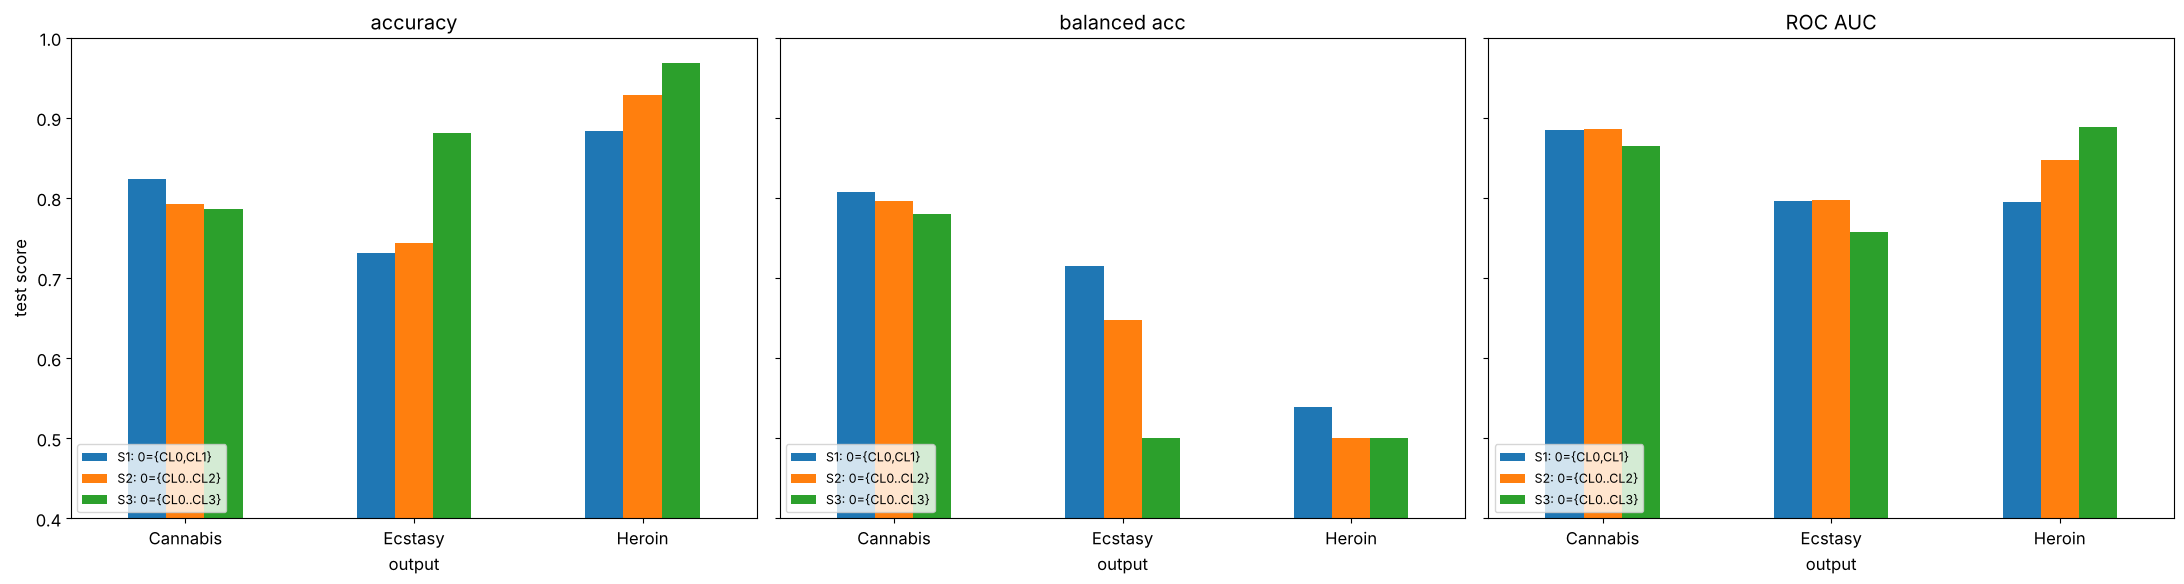

Best setup per drug and metric:


,balanced acc,F1 (class 1),ROC AUC,CV ROC AUC
output,,,,
Cannabis,"S1: 0={CL0,CL1}","S1: 0={CL0,CL1}",S2: 0={CL0..CL2},S2: 0={CL0..CL2}
Ecstasy,"S1: 0={CL0,CL1}","S1: 0={CL0,CL1}",S2: 0={CL0..CL2},S2: 0={CL0..CL2}
Heroin,"S1: 0={CL0,CL1}","S1: 0={CL0,CL1}",S3: 0={CL0..CL3},S2: 0={CL0..CL2}


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6), sharey=True)
for ax, metric in zip(axes, ["accuracy", "balanced acc", "ROC AUC"]):
    results_t2d[metric].unstack("setup").plot.bar(ax=ax, rot=0)
    ax.set_title(metric); ax.set_ylim(0.4, 1.0); ax.legend(fontsize=9, loc="lower left")
axes[0].set_ylabel("test score")
plt.tight_layout(); plt.show()

best = pd.DataFrame({m: results_t2d.groupby(level="output")[m].idxmax().map(lambda t: t[1])
                     for m in ["balanced acc", "F1 (class 1)", "ROC AUC", "CV ROC AUC"]})
print("Best setup per drug and metric:"); best

**Comment (d).**

* **Binary problems are much easier than the 7-class problem**: ROC AUC is 0.76–0.89 for all drugs and setups, i.e. demographics + personality separate users from non-users quite well.
* **Cannabis** (common drug): all setups work well (accuracy 0.79–0.82, AUC ≈ 0.87–0.89). **S1** gives the best accuracy (0.82), balanced accuracy (0.81) and F1 (0.87); S2 has practically the same AUC (0.886 vs 0.885) and the best CV AUC. Accuracy gain over the baseline is largest for S2/S3 because their classes are more balanced.
* **Ecstasy**: **S1** is best by balanced accuracy (0.72) and F1 (0.66); S2 has the same AUC (0.80) but lower balanced accuracy (0.65). In **S3** only 12 % of people are class 1, and with the default 0.5 threshold the model *never* predicts class 1: accuracy 0.88 looks good but equals the baseline, balanced accuracy = 0.50 and F1 = 0.
* **Heroin** (rare drug): accuracy 0.88–0.97 is only the majority baseline. The model predicts class 1 only a few times in S1 (balanced accuracy 0.54, F1 0.15) and never in S2/S3. The AUC (0.80–0.89) shows the *ranking* of risk is still informative, so a lower decision threshold or `class_weight="balanced"` would recover users. (The high test AUC of S3 rests on only 15 positive test cases; the CV AUC is ≈ 0.82 for all setups.)
* **Best setup: S1** (class 0 = "Never Used" + "Used over a Decade Ago"). It gives the most balanced classes and the best balanced accuracy and F1 for all three drugs, with AUC equal to or very close to the best; it also matches the "user vs non-user" split used in the reference paper (Fehrman et al., 2017). S2/S3 only look better in plain accuracy for Ecstasy/Heroin because of the growing class imbalance — a reminder from the lecture to always compare with a baseline and not to rely on accuracy alone.

## Task 3 (5 points): Data normalization

##### Dataset: Linnerud
* Number of records: 20
* Number of features: 3 + 3 (target/output features)
* Repository URL: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_linnerud.html

##### Problems
__a.__ Look at features of Linnerud dataset, explore them and describe their characteristics. \
__b.__ Normalize these features using an appropriate method. Plot the probability density function of each feature with original and normalized data side-by-side.

In [ ]:
from sklearn.datasets import load_linnerud
linnerud = load_linnerud(as_frame=True)
X_lin = linnerud.data            # exercise features: Chins, Situps, Jumps
Y_lin = linnerud.target          # physiological targets: Weight, Waist, Pulse
print(linnerud.DESCR[:900])
pd.concat([X_lin, Y_lin], axis=1).head()

In [ ]:
desc = X_lin.describe().T
desc["skewness"] = X_lin.skew()
desc["IQR"] = desc["75%"] - desc["25%"]
desc["outliers (1.5·IQR rule)"] = [int(((X_lin[c] < q1 - 1.5 * iqr) | (X_lin[c] > q3 + 1.5 * iqr)).sum())
                                   for c, q1, q3, iqr in zip(X_lin.columns, desc["25%"], desc["75%"], desc["IQR"])]
desc.round(2)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))
sns.boxplot(data=X_lin, ax=axes[0]); axes[0].set_title("Feature ranges (raw units)")
for c in X_lin.columns:
    sns.kdeplot(X_lin[c], ax=axes[1], label=c, fill=True, alpha=0.2)
axes[1].set_title("Densities on the original scale"); axes[1].legend()
sns.heatmap(pd.concat([X_lin, Y_lin], axis=1).corr(), annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, ax=axes[2])
axes[2].set_title("Pearson correlations (features + targets)")
plt.tight_layout(); plt.show()

**a. Characteristics of the features**

* The data set is tiny: **20 middle-aged men**, 3 exercise features — *Chins* (chin-ups), *Situps* (sit-ups) and *Jumps* (jumping jacks) — all **non-negative integer counts**, no missing values. The 3 targets are physiological (Weight, Waist, Pulse).
* The features are on **very different scales**: Chins 1–17 (mean ≈ 9.5, std ≈ 5.3), Situps 50–251 (mean ≈ 146, std ≈ 63), Jumps 25–250 (mean ≈ 70, std ≈ 51). Any distance-based or regularised model would be dominated by Situps/Jumps without scaling.
* **Shape:** Chins and Situps are roughly symmetric (skewness ≈ –0.2 and 0.2) and somewhat bimodal (a group of fit and a group of less fit men). **Jumps is strongly right-skewed (skewness ≈ 2.5)** with one clear **outlier** (250 jumps, while 75 % of the men do ≤ 85).
* The features are positively correlated with each other (Chins–Situps 0.70, Situps–Jumps 0.67, Chins–Jumps 0.50) and negatively correlated with Weight and Waist (e.g. Situps–Waist –0.65: slimmer men do more repetitions).

**b. Choice of method.** Lecture 2 compared `StandardScaler`, `MinMaxScaler`, `RobustScaler` and `Normalizer`:

* `Normalizer` rescales each *row* (sample) to unit length — not what we want for features.
* `MinMaxScaler` and `StandardScaler` rely on min/max and on mean/std; the Jumps outlier (250) would squeeze the other 19 values into a small part of the range (Min-Max) or inflate the standard deviation (Standard).
* **`RobustScaler`** centres on the **median** and scales by the **inter-quartile range**, so it is not influenced by the outlier. Because the features have different scales *and* one has an outlier, `RobustScaler` is the appropriate choice here. (With only 20 samples and no train/test split in this task, the scaler is fitted on all 20 rows.)

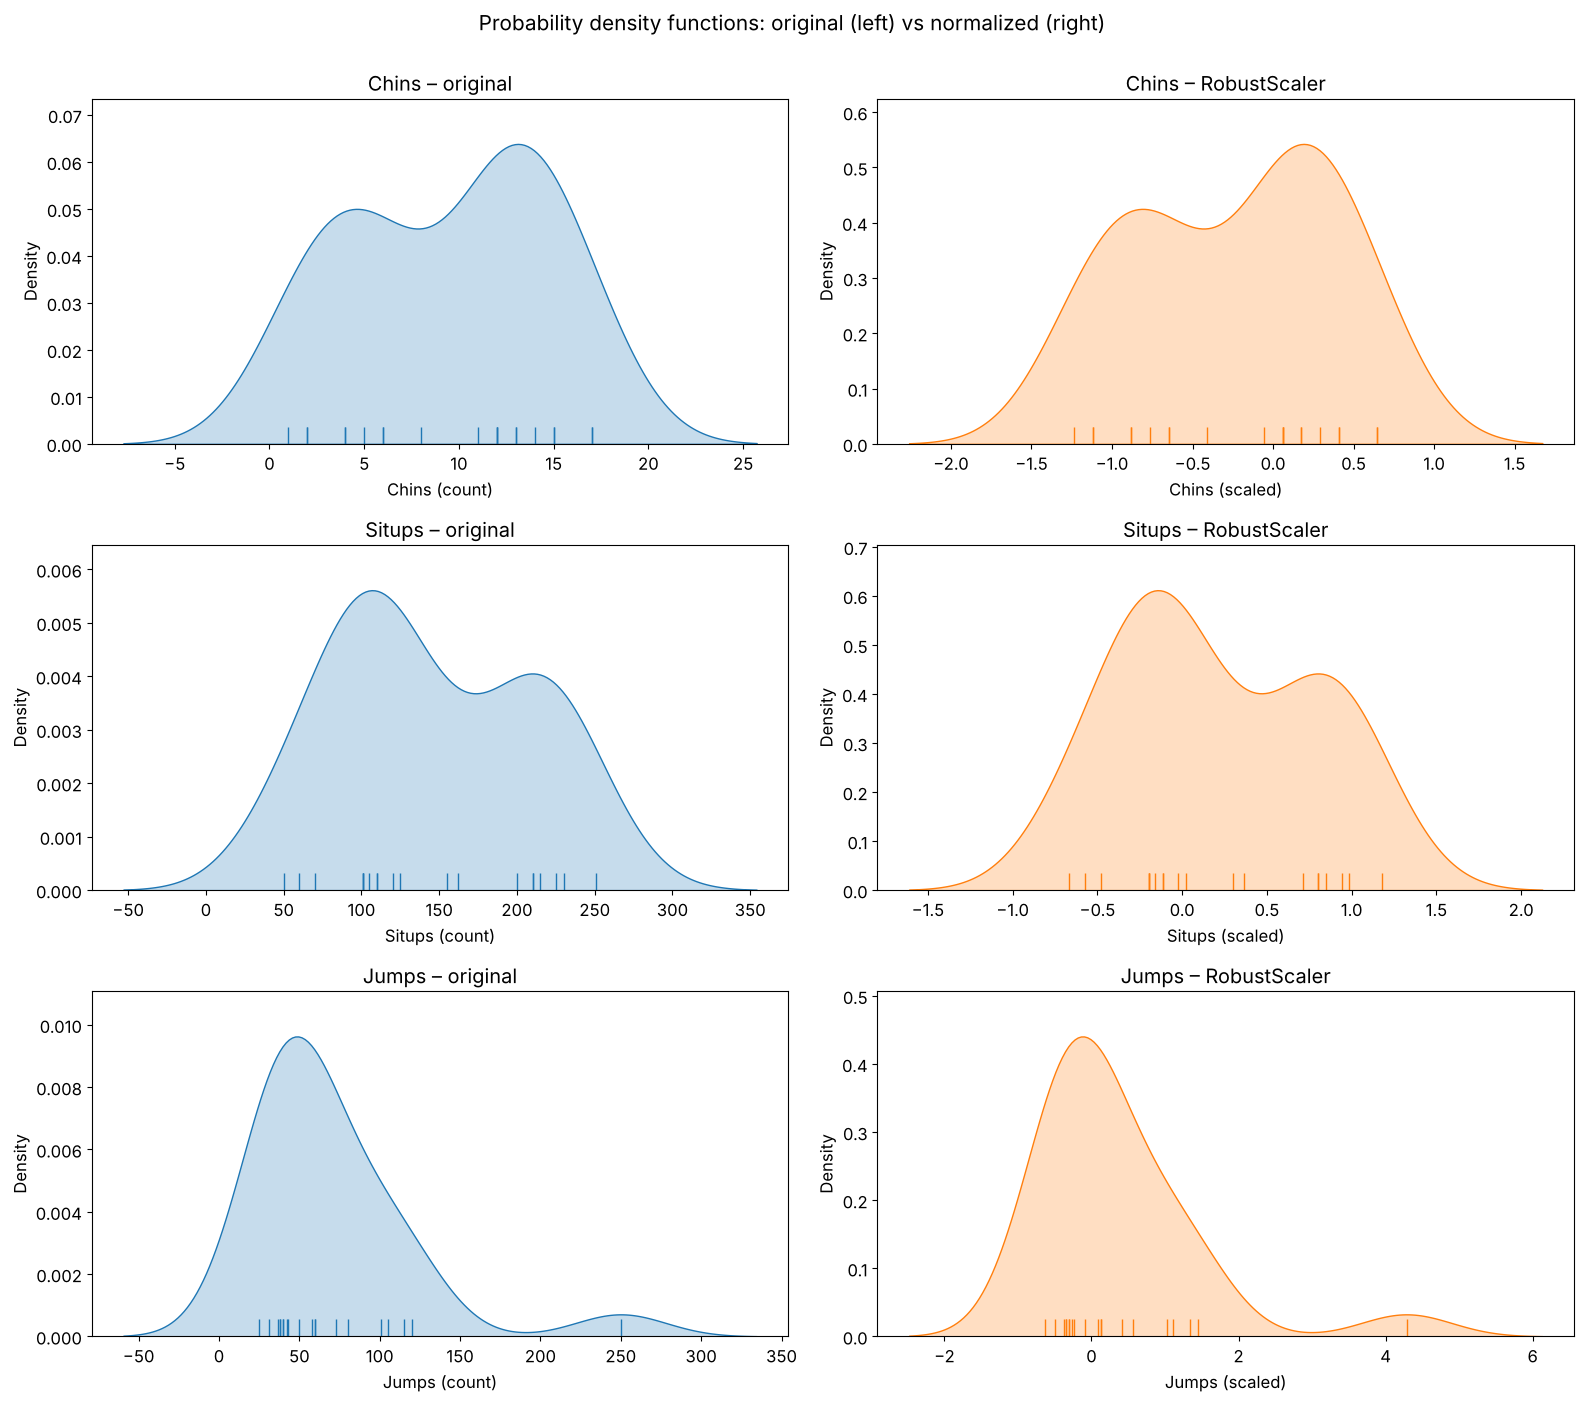

In [20]:
scaler_lin = RobustScaler()
X_lin_norm = pd.DataFrame(scaler_lin.fit_transform(X_lin), columns=X_lin.columns)

fig, axes = plt.subplots(3, 2, figsize=(16, 14))
for i, c in enumerate(X_lin.columns):
    sns.kdeplot(X_lin[c], ax=axes[i, 0], fill=True, color="tab:blue")
    sns.rugplot(X_lin[c], ax=axes[i, 0], color="tab:blue", height=0.05)
    axes[i, 0].set_title(f"{c} – original"); axes[i, 0].set_xlabel(f"{c} (count)")
    sns.kdeplot(X_lin_norm[c], ax=axes[i, 1], fill=True, color="tab:orange")
    sns.rugplot(X_lin_norm[c], ax=axes[i, 1], color="tab:orange", height=0.05)
    axes[i, 1].set_title(f"{c} – RobustScaler"); axes[i, 1].set_xlabel(f"{c} (scaled)")
plt.suptitle("Probability density functions: original (left) vs normalized (right)", y=1.0, fontsize=15)
plt.tight_layout(); plt.show()

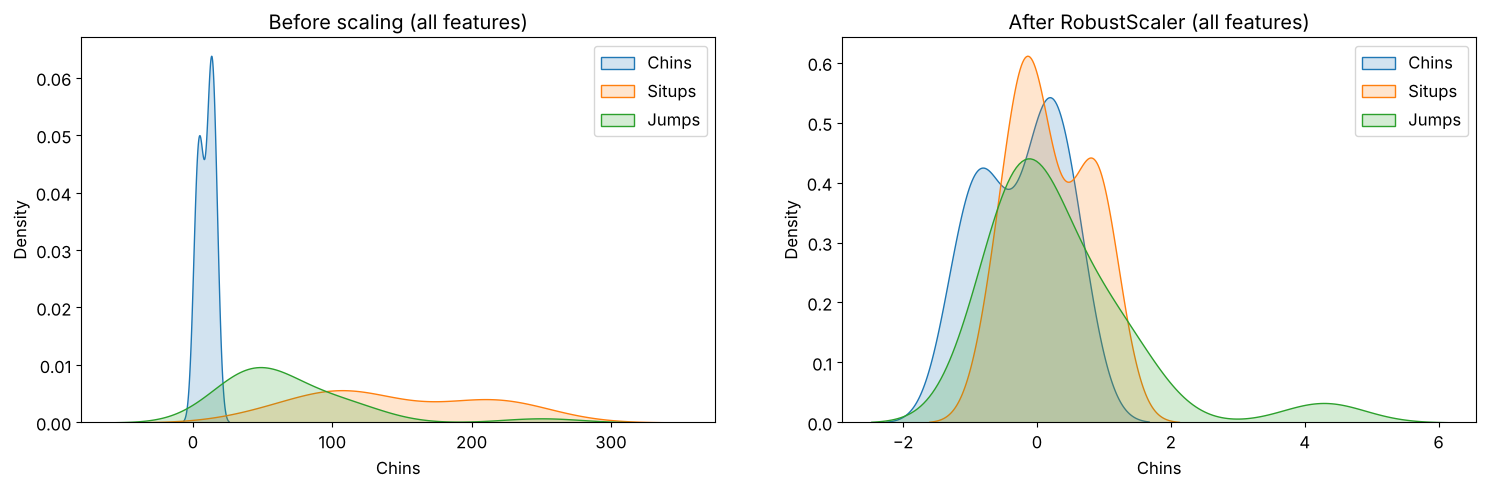

Chins             Situps              Jumps            
               median   min   max median   min   max median   min   max
StandardScaler   0.40 -1.64  1.47  -0.38 -1.57  1.73  -0.33 -0.91  3.60
MinMaxScaler     0.66  0.00  1.00   0.36  0.00  1.00   0.13  0.00  1.00
RobustScaler     0.00 -1.24  0.65   0.00 -0.67  1.18   0.00 -0.63  4.28

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for c in X_lin.columns:
    sns.kdeplot(X_lin[c], ax=axes[0], label=c, fill=True, alpha=0.2)
    sns.kdeplot(X_lin_norm[c], ax=axes[1], label=c, fill=True, alpha=0.2)
axes[0].set_title("Before scaling (all features)"); axes[1].set_title("After RobustScaler (all features)")
axes[0].legend(); axes[1].legend(); plt.show()

# Compare with the other scalers from the lecture
comp = {}
for name, sc in {"StandardScaler": StandardScaler(), "MinMaxScaler": MinMaxScaler(),
                 "RobustScaler": RobustScaler()}.items():
    Z = pd.DataFrame(sc.fit_transform(X_lin), columns=X_lin.columns)
    comp[name] = Z.agg(["median", "min", "max"]).T.round(2).stack()
pd.DataFrame(comp).T

**Comment (b).** After robust scaling all three features are centred at a median of 0 and have an inter-quartile range of 1, so they are directly comparable and can be plotted on one axis. The *shape* of each density is unchanged — scaling is a linear transformation, so it does not remove skewness (Jumps keeps its long right tail and the outlier stays visible at ≈ +4.3, it is simply not allowed to dictate the scale of the other points). The comparison table shows why the other scalers are less suitable: with `MinMaxScaler`, 19 of the 20 Jumps values are squeezed into [0, 0.42] because of the single outlier; `StandardScaler` uses a standard deviation inflated by the same point. If a more symmetric (Gaussian-like) shape were also desired, a non-linear `PowerTransformer` (Yeo-Johnson, see the lecture's extra section) could be applied to Jumps.

## Task 4 ( 10 points):  Dimensionality reduction and clustering
In case there is not Olivetti dataset, please change this into another dataset

##### Dataset: The Olivetti faces dataset
* Number of records: 400
* Number of features: 4096
* Repository URL: https://scikit-learn.org/stable/datasets/real_world.html

##### Problems
__a.__ Use KernelPCA\* for dimensionality reduction. Train a classifier at different numbers (at least 5 values) of dimensions, then check how model score changes as a function of the number of dimensions. \
__b.__ Cluster the dataset into 40 clusters for at least 2 of the reduced data (done by KernelPCA in a). Print true class vs cluster distribution. Did you manage to recover the original clusters? Describe and comment your results. \

\* Marukatat, S. Tutorial on PCA and approximate PCA and approximate kernel PCA. Artif Intell Rev 56, 5445–5477 (2023). https://doi.org/10.1007/s10462-022-10297-z

In [12]:
from sklearn.datasets import fetch_olivetti_faces
faces = fetch_olivetti_faces()            # downloads once (~1.5 MB), then cached in ~/scikit_learn_data
X_f, y_f = faces.data, faces.target       # pixels already scaled to [0, 1]
image_shape = faces.images[0].shape
print("data:", X_f.shape, " image:", image_shape, " people:", len(np.unique(y_f)),
      " images per person:", np.bincount(y_f)[0])

downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to C:\Users\test\scikit_learn_data
data: (400, 4096)  image: (64, 64)  people: 40  images per person: 10


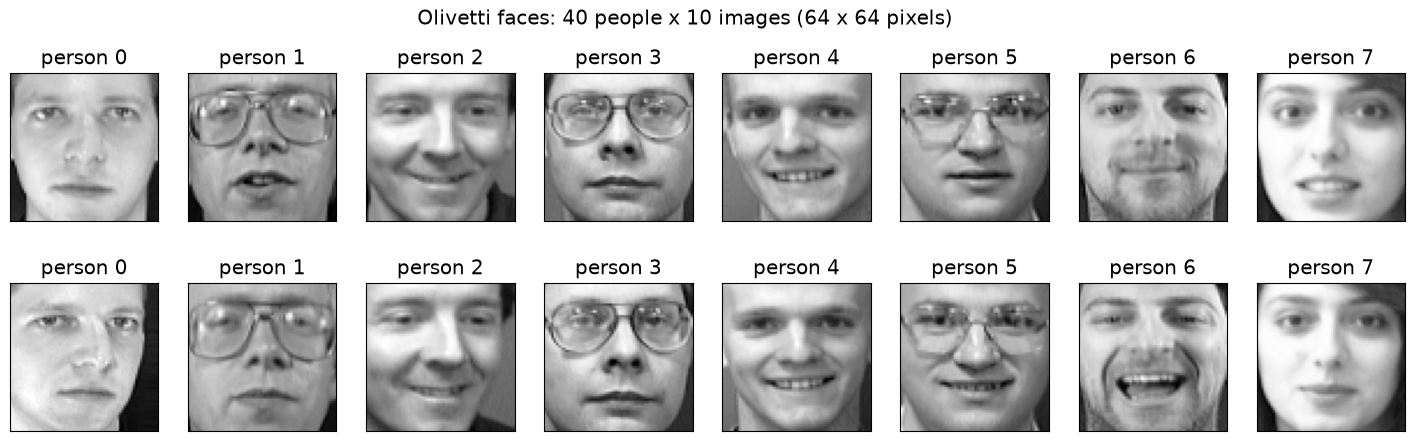

In [13]:
fig, axes = plt.subplots(2, 8, figsize=(18, 5), subplot_kw={"xticks": (), "yticks": ()})
for ax, i in zip(axes.ravel(), np.r_[0:80:10, 1:80:10][:16]):
    ax.imshow(X_f[i].reshape(image_shape), cmap="gray"); ax.set_title(f"person {y_f[i]}")
plt.suptitle("Olivetti faces: 40 people x 10 images (64 x 64 pixels)"); plt.show()

### a. Kernel PCA + classifier for different numbers of dimensions

Following the eigenfaces example in Lecture 2: stratified train/test split (7–8 training images per person), dimensionality reduction fitted **on the training images only**, then a **1-nearest-neighbour** classifier on the reduced features. Kernel PCA uses an RBF kernel; we vary the number of components over 8 values and compare with 1-NN on the raw 4096 pixels and with ordinary (linear) PCA.

In [14]:
from sklearn.decomposition import KernelPCA, PCA
from sklearn.neighbors import KNeighborsClassifier

Xf_tr, Xf_te, yf_tr, yf_te = train_test_split(X_f, y_f, test_size=0.25, stratify=y_f, random_state=0)
print("train:", Xf_tr.shape, " test:", Xf_te.shape)

raw_acc = KNeighborsClassifier(n_neighbors=1).fit(Xf_tr, yf_tr).score(Xf_te, yf_te)
print(f"1-NN on raw pixels (4096 dims): test accuracy = {raw_acc:.3f}")

n_dims = [2, 5, 10, 20, 40, 80, 150, 200]   # max 240 = size of a CV training fold
rows = []
for k in n_dims:
    for name, reducer in {"KernelPCA (rbf)": KernelPCA(n_components=k, kernel="rbf"),
                          "PCA (linear)":    PCA(n_components=k, random_state=0)}.items():
        pipe = make_pipeline(reducer, KNeighborsClassifier(n_neighbors=1))
        cv_acc = cross_val_score(pipe, Xf_tr, yf_tr, cv=StratifiedKFold(5, shuffle=True, random_state=0)).mean()
        pipe.fit(Xf_tr, yf_tr)
        rows.append({"n_components": k, "reducer": name, "CV accuracy": cv_acc,
                     "test accuracy": pipe.score(Xf_te, yf_te)})
results_t4a = pd.DataFrame(rows)
results_t4a.pivot(index="n_components", columns="reducer", values=["CV accuracy", "test accuracy"]).round(3)

train: (300, 4096)  test: (100, 4096)
1-NN on raw pixels (4096 dims): test accuracy = 0.930


CV accuracy                test accuracy             
reducer      KernelPCA (rbf) PCA (linear) KernelPCA (rbf) PCA (linear)
n_components                                                          
2                      0.277        0.273            0.26         0.26
5                      0.653        0.650            0.73         0.75
10                     0.797        0.803            0.88         0.88
20                     0.877        0.877            0.90         0.91
40                     0.897        0.897            0.91         0.91
80                     0.910        0.910            0.93         0.93
150                    0.907        0.907            0.93         0.93
200                    0.907        0.907            0.93         0.93

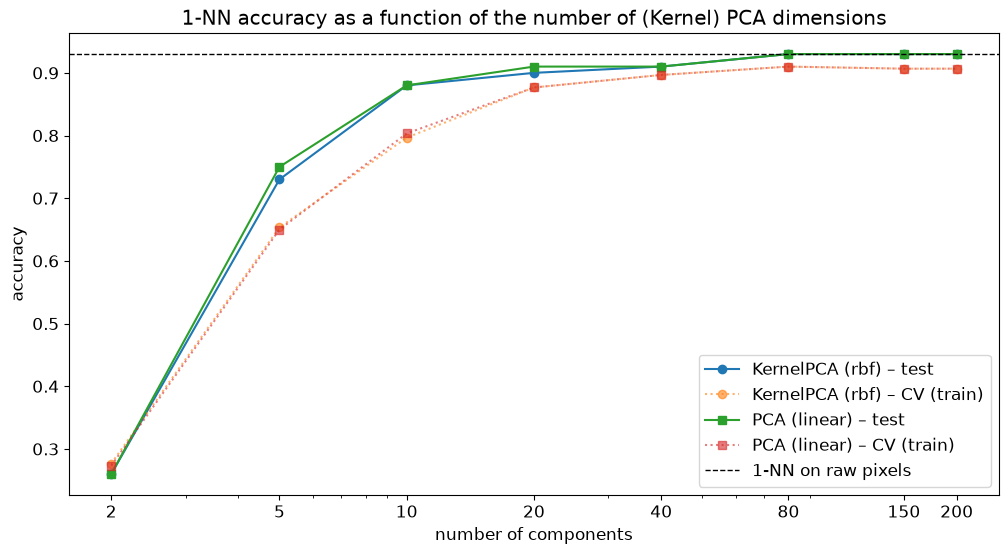

In [15]:
fig, ax = plt.subplots(figsize=(12, 6))
for (name, g), mk in zip(results_t4a.groupby("reducer"), ["o", "s"]):
    ax.plot(g["n_components"], g["test accuracy"], mk + "-", label=f"{name} – test")
    ax.plot(g["n_components"], g["CV accuracy"], mk + ":", alpha=0.6, label=f"{name} – CV (train)")
ax.axhline(raw_acc, c="k", ls="--", lw=1, label="1-NN on raw pixels")
ax.set_xscale("log"); ax.set_xticks(n_dims); ax.set_xticklabels(n_dims)
ax.set_xlabel("number of components"); ax.set_ylabel("accuracy")
ax.set_title("1-NN accuracy as a function of the number of (Kernel) PCA dimensions"); ax.legend()
plt.show()

In [16]:
best_row = results_t4a[results_t4a.reducer == "KernelPCA (rbf)"].sort_values("CV accuracy", ascending=False).iloc[0]
print(f"Kernel PCA: best number of components by CV = {int(best_row.n_components)}, "
      f"test accuracy = {best_row['test accuracy']:.3f}  (raw pixels: {raw_acc:.3f})")

Kernel PCA: best number of components by CV = 80, test accuracy = 0.930  (raw pixels: 0.930)


**Comment (a).**

* With only **2–5 components** the faces cannot be separated (accuracy far below the raw-pixel 1-NN): a few directions of maximum variance mostly describe lighting and head pose, not identity.
* Accuracy rises steeply up to **~20–40 components** and then reaches a plateau at about the level of 1-NN on all 4096 pixels. Adding more components after this point only adds low-variance directions (noise/fine details) and does not help — the identity information is compressed into a few dozen dimensions, i.e. a **> 100× reduction** of the feature space with no loss in accuracy (and much faster distance computations).
* Kernel PCA with an RBF kernel behaves very similarly to linear PCA here. With the default `gamma = 1/n_features` the RBF kernel is quite smooth over the range of distances between face images, so the kernel feature space is close to the linear one; the non-linear kernel does not give a clear advantage on this data set (a result also discussed in the Marukatat tutorial: kernel PCA pays off when the structure is strongly non-linear).
* CV scores (dotted) and test scores follow the same curve, so the choice of the number of components is not just a lucky test split.

### b. Clustering the reduced data into 40 clusters

Clustering is unsupervised, so Kernel PCA is now fitted on all 400 images (the labels are used only afterwards, to evaluate). We use **two reduced data sets** from a — **20** and **80** Kernel-PCA components — and the two clustering algorithms from Lecture 2, **k-Means** and **agglomerative (Ward) clustering**, each with 40 clusters.

To compare true classes and clusters (cluster numbers are arbitrary) we use:
* the **contingency table** true class × cluster (`pd.crosstab`) — printed and shown as a heatmap;
* for each person: the **dominant cluster** and how many of the 10 images fall into it;
* **purity** (fraction of images that belong to the majority person of their cluster), **ARI** (adjusted Rand index, 1 = perfect, 0 = random) and **NMI**;
* a person counts as **recovered** if ≥ 8 of their 10 images share one cluster *and* that cluster is ≥ 80 % that person.

In [22]:
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

def cluster_report(y_true, labels):
    ct = pd.crosstab(pd.Series(y_true, name="true class"), pd.Series(labels, name="cluster"))
    dom_cluster = ct.idxmax(axis=1)
    dom_count = ct.max(axis=1)
    cluster_purity = ct.max(axis=0) / ct.sum(axis=0)
    recovered = [(dom_count[c] >= 8) and (cluster_purity[dom_cluster[c]] >= 0.8) for c in ct.index]
    per_class = pd.DataFrame({"dominant cluster": dom_cluster, "images in it (of 10)": dom_count,
                              "n clusters used": (ct > 0).sum(axis=1),
                              "purity of that cluster": cluster_purity[dom_cluster].to_numpy().round(2),
                              "recovered": recovered})
    metrics = {"ARI": adjusted_rand_score(y_true, labels),
               "NMI": normalized_mutual_info_score(y_true, labels),
               "purity": ct.max(axis=0).sum() / ct.to_numpy().sum(),
               "people recovered (of 40)": int(np.sum(recovered)),
               "non-empty clusters": ct.shape[1],
               "largest cluster size": int(ct.sum(axis=0).max())}
    return ct, per_class, metrics

reduced = {k: KernelPCA(n_components=k, kernel="rbf").fit_transform(X_f) for k in (20, 80)}
clusterers = {"k-Means": lambda: KMeans(n_clusters=40, n_init=20, random_state=0),
              "Agglomerative (ward)": lambda: AgglomerativeClustering(n_clusters=40, linkage="ward")}

reports, all_metrics = {}, {}
for k, Z in reduced.items():
    for cname, make in clusterers.items():
        labels = make().fit_predict(Z)
        reports[(k, cname)] = (labels, *cluster_report(y_f, labels))
        all_metrics[(f"KPCA {k} dims", cname)] = reports[(k, cname)][3]

metrics_t4b = pd.DataFrame(all_metrics).T
metrics_t4b.round(3)

ARI    NMI  purity  people recovered (of 40)  non-empty clusters  largest cluster size
KPCA 20 dims k-Means               0.422  0.769   0.605                       6.0                40.0                  21.0
             Agglomerative (ward)  0.442  0.786   0.622                       8.0                40.0                  25.0
KPCA 80 dims k-Means               0.460  0.791   0.655                       9.0                40.0                  25.0
             Agglomerative (ward)  0.520  0.825   0.695                       8.0                40.0                  25.0

In [23]:
# True class vs cluster distribution (full contingency tables), one per reduced data set
pd.set_option("display.max_columns", 50); pd.set_option("display.width", 250)
for k in reduced:
    labels, ct, per_class, m = reports[(k, "k-Means")]
    # order clusters by the person that dominates them -> a good clustering appears as a diagonal
    ct_sorted = ct[sorted(ct.columns, key=lambda c: (ct[c].idxmax(), -ct[c].max()))]
    print(f"\n=== Kernel PCA {k} dims + k-Means: true class (rows) vs cluster (columns) ===")
    print(ct_sorted.to_string())


=== Kernel PCA 20 dims + k-Means: true class (rows) vs cluster (columns) ===
cluster     35  24  3   22  34  39  23  27  10  8   30  6   5   20  33  0   37  26  29  38  36  9   25  11  2   16  28  19  7   17  31  12  21  14  4   13  15  18  32  1 
true class                                                                                                                                                                
0            5   0   0   0   0   0   1   2   0   0   0   0   0   0   1   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   1   0   0   0   0   0
1            0  10   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
2            0   0   2   0   0   0   0   0   0   0   0   0   0   0   0   2   0   0   0   0   0   0   0   0   3   0   0   2   0   0   0   0   0   0   0   0   0   1   0   0
3            0   0   0   0   0   0   0   0   0   0   0   0   1   4 

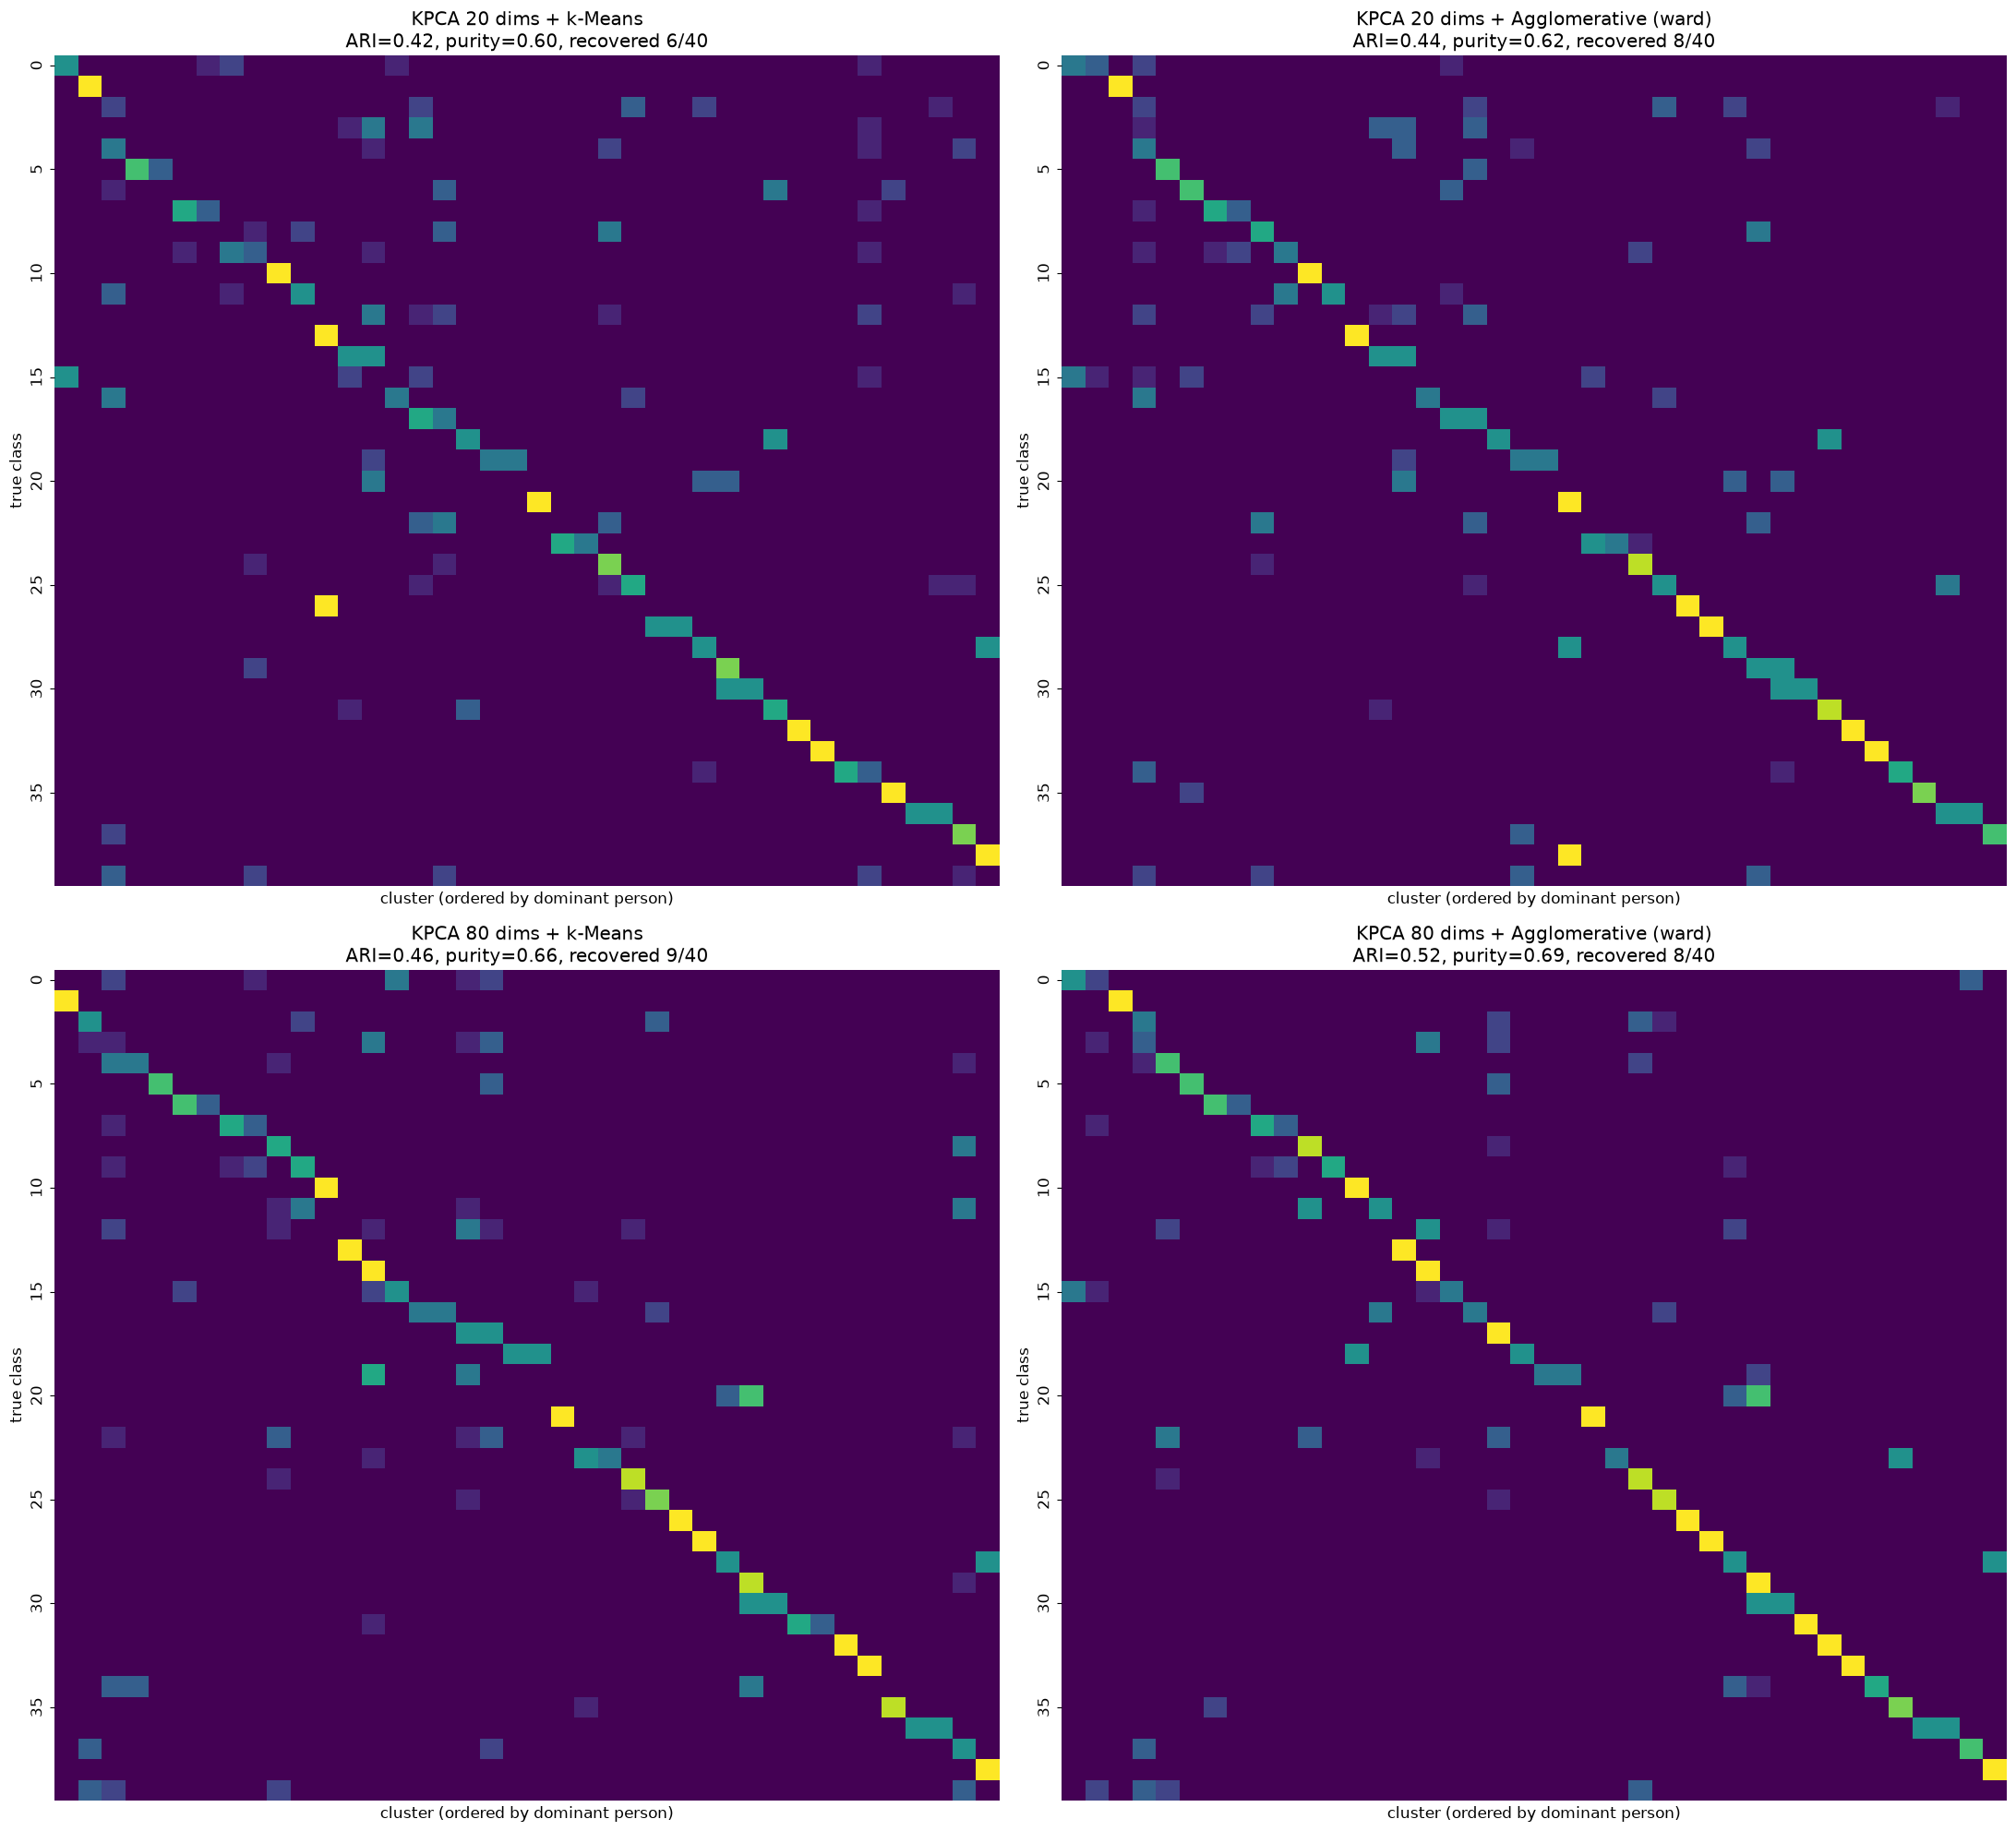

In [24]:
fig, axes = plt.subplots(2, 2, figsize=(22, 20))
for ax, ((k, cname), (labels, ct, per_class, m)) in zip(axes.ravel(), reports.items()):
    ct_sorted = ct[sorted(ct.columns, key=lambda c: (ct[c].idxmax(), -ct[c].max()))]
    sns.heatmap(ct_sorted, cmap="viridis", cbar=False, ax=ax, xticklabels=False, yticklabels=5)
    ax.set_title(f"KPCA {k} dims + {cname}\nARI={m['ARI']:.2f}, purity={m['purity']:.2f}, "
                 f"recovered {m['people recovered (of 40)']}/40")
    ax.set_xlabel("cluster (ordered by dominant person)")
plt.tight_layout(); plt.show()

In [25]:
# Per-person view for the best configuration
best_cfg = max(reports, key=lambda key: reports[key][3]["ARI"])
labels_best, ct_best, per_class_best, m_best = reports[best_cfg]
print(f"Best configuration: Kernel PCA {best_cfg[0]} dims + {best_cfg[1]}  (ARI = {m_best['ARI']:.3f})")
print("Distribution of 'images of a person in its dominant cluster':")
print(per_class_best["images in it (of 10)"].value_counts().sort_index(ascending=False).to_string())
per_class_best

Best configuration: Kernel PCA 80 dims + Agglomerative (ward)  (ARI = 0.520)
Distribution of 'images of a person in its dominant cluster':
images in it (of 10)
10    13
9      3
8      1
7      5
6      3
5      8
4      6
3      1


,dominant cluster,images in it (of 10),n clusters used,purity of that cluster,recovered
true class,,,,,
0,20,5,3,0.56,False
1,9,10,1,1.00,True
2,7,4,4,0.29,False
3,5,4,4,0.48,False
4,31,7,3,0.44,False
5,26,7,2,1.00,False
6,15,7,2,0.78,False
7,38,6,3,0.86,False
8,0,9,2,0.53,False


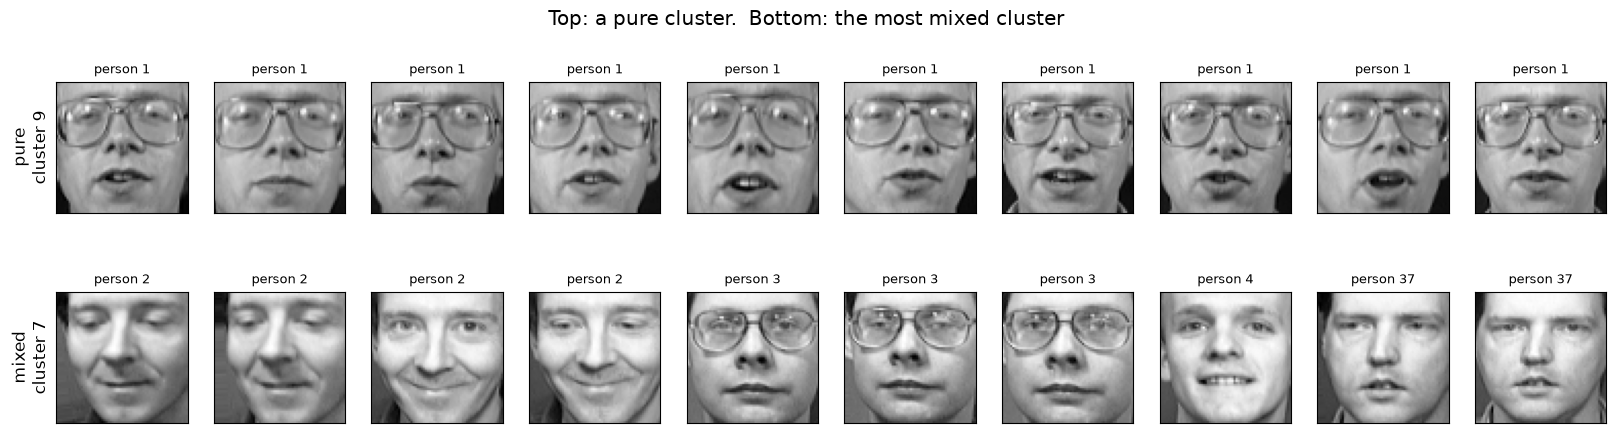

In [26]:
# Look inside: a pure cluster and the most mixed cluster of the best configuration
sizes = ct_best.sum(axis=0)
purity_c = ct_best.max(axis=0) / sizes
pure_c = purity_c[sizes >= 5].sort_values(ascending=False).index[0]
mixed_c = purity_c[sizes >= 4].sort_values().index[0]

fig, axes = plt.subplots(2, 10, figsize=(20, 5), subplot_kw={"xticks": (), "yticks": ()})
for row, c, title in ((0, pure_c, "pure"), (1, mixed_c, "mixed")):
    idx = np.where(labels_best == c)[0][:10]
    for ax in axes[row]: ax.axis("off")
    for ax, i in zip(axes[row], idx):
        ax.axis("on"); ax.imshow(X_f[i].reshape(image_shape), cmap="gray"); ax.set_title(f"person {y_f[i]}", fontsize=9)
    axes[row, 0].set_ylabel(f"{title}\ncluster {c}")
plt.suptitle("Top: a pure cluster.  Bottom: the most mixed cluster"); plt.show()

**Comment (b).** *(Numbers refer to the tables printed above.)*

* **Partly recovered.** The clusters are far from random — ARI and NMI are well above 0 and the sorted contingency heatmaps show a clear (but imperfect) diagonal — yet **not all 40 people are recovered**. Many people have all or almost all of their 10 images in one pure cluster, while others are **split** over 2–4 clusters, and some clusters **merge** images of two or more different people.
* **Why errors happen:** the clustering algorithms only see Euclidean distances in the reduced space. Differences in **lighting, pose (head turned), facial expression and glasses** between images of the *same* person can be larger than the difference between two *similar-looking* people. The mixed cluster shown above typically contains people with similar lighting/face shape, and people who sometimes wear glasses are often split.
* **k-Means vs agglomerative:** k-Means assumes compact, roughly spherical clusters of similar size; with only 10 points per cluster in 20–80 dimensions it is sensitive to initialisation (hence `n_init=20`). Ward agglomerative clustering builds the hierarchy from the closest pairs and often gives similar or slightly better purity on this data; both produce some very small and some too-large clusters, whereas the true clusters all have exactly 10 images.
* **20 vs 80 dimensions:** the results are of the same order. More dimensions keep more identity detail but also more noise and make distances more uniform (curse of dimensionality, Lecture 1), so going from 20 to 80 components does not dramatically improve the clustering — consistent with the plateau seen in part a.
* **Supervised vs unsupervised:** in part a a 1-NN classifier on the same Kernel-PCA features identified the large majority of the test faces correctly, because it is told which images belong together. Without labels, recovering exactly 40 groups of 10 is much harder, so a partial recovery is the expected result for this data set.

In [ ]:
This solution was prepared with the help of Claude (Anthropic). I used it to write and debug the code and to draft the comments, 
following the methods from Lectures 1 and 2. I ran the full notebook myself, checked the results, and reviewed the explanations.
    